# 04 — Exploratory Data Analysis (EDA) Data Fenotipik ABIDE II

Notebook 03 menganalisis fenotipik **ABIDE I**. Notebook ini melakukan hal yang sama untuk **ABIDE II**, sebelum kedua dataset digabung dan dibersihkan di notebook 05.

| | |
| :--- | :--- |
| **Masukan** | 16 berkas `participants.tsv`, satu per situs, di `data/raw_dcan/abide2_participants/` (diunduh `tools/download_dcan.py` dari repositori publik ABIDE II) |
| **Keluaran** | `data/phenotypic/Phenotypic_ABIDE2_raw.csv`: gabungan mentah 16 situs, **tanpa diubah isinya** (dipakai notebook 05) · tabel `result/tabel/02a_*.csv` · gambar `result/figure/02a_*.png` |
| **Tidak dilakukan di sini** | pembersihan, imputasi, dan penggabungan dengan ABIDE I. Semua itu dikerjakan di notebook 05 |

### Isi notebook

| Bagian | Isi |
| :---: | :--- |
| 1 | Mengumpulkan data mentah: 19 situs ABIDE II, 16 punya berkas fenotipik |
| 2 | Kamus kolom: 348 kolom dikelompokkan menurut fungsinya |
| 3 | Kode nilai kosong di ABIDE II (berbeda dengan ABIDE I) |
| 4 | Distribusi diagnosis per situs |
| 5 | Profil subjek: usia, jenis kelamin, IQ, tangan dominan |
| 6 | Nilai kosong per kolom |
| 7 | Kolom yang dipakai dan dibuang, beserta alasannya |
| 8 | Ketersediaan data citra (turunan DCAN) untuk setiap subjek |
| 9 | Ringkasan |

## Persiapan

In [1]:
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
TSV_DIR = ROOT / "data" / "raw_dcan" / "abide2_participants"
DCAN_A2 = ROOT / "data" / "raw_dcan" / "abide2"
PHENO_DIR = ROOT / "data" / "phenotypic"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
for d in (TABEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def simpan_tabel(df, nama):
    df.to_csv(TABEL_DIR / f"02a_{nama}.csv")

WARNA = {"ASD": "#DD6B20", "Kontrol": "#2F855A"}
print("Folder berkas fenotipik ABIDE II:", TSV_DIR)

Folder berkas fenotipik ABIDE II: c:\Users\hikma\Documents\Tugas Akhir\v7\data\raw_dcan\abide2_participants


## 1. Mengumpulkan Data Mentah

ABIDE II terdiri dari **19 situs** (rumah sakit/universitas). Fenotipik setiap situs disimpan terpisah dalam berkas `participants.tsv` (format teks dengan pemisah tab).

| Situs tanpa berkas fenotipik di repositori | Akibat |
| :--- | :--- |
| ETHZ_1, UCLA_Long, UPSM_Long | tidak ada label diagnosis, sehingga subjeknya tidak bisa dipakai |

Langkah di sel berikut:
1. membaca 16 berkas `participants.tsv` (*encoding* latin-1, karena ada karakter khusus di kolom teks);
2. **membuang spasi di nama kolom**. Contoh: nama kolom usia tertulis `"age_at_scan "` (ada spasi di akhir), yang kalau tidak dibersihkan membuat kolom itu tidak terbaca dengan nama `age_at_scan`;
3. menggabungkan 16 situs menjadi satu tabel, lalu menyimpannya sebagai `Phenotypic_ABIDE2_raw.csv`. **Isinya tidak diubah**: tidak ada baris atau kolom yang dibuang.

Berkas `Phenotypic_ABIDE2_raw.csv` sudah pernah dibuat. Jadi sel ini **tidak menimpanya**, tetapi membandingkan berkas yang ada dengan hasil penggabungan di sini.

In [2]:
SITUS_ABIDE2 = ["BNI_1", "EMC_1", "ETHZ_1", "GU_1", "IP_1", "IU_1", "KKI_1", "KUL_3", "NYU_1", "NYU_2", "OHSU_1", "ONRC_2",
                "SDSU_1", "TCD_1", "UCD_1", "UCLA_1", "UCLA_Long", "UPSM_Long", "USM_1"]
berkas = {Path(f).stem.replace("ABIDEII-", ""): f for f in sorted(glob.glob(str(TSV_DIR / "*.tsv")))}
per_situs = []
tabel = []
for s in SITUS_ABIDE2:
    if s in berkas:
        t = pd.read_csv(berkas[s], sep="\t", encoding="latin-1")
        spasi = [c for c in t.columns if c != c.strip()]
        t = t.rename(columns=lambda c: c.strip())
        tabel.append(t)
        per_situs.append({"Situs": s, "Berkas fenotipik": "ada", "Subjek": len(t), "Kolom": t.shape[1], "Nama kolom berspasi": ", ".join(repr(c) for c in spasi) or "-"})
    else:
        per_situs.append({"Situs": s, "Berkas fenotipik": "TIDAK ADA", "Subjek": 0, "Kolom": 0, "Nama kolom berspasi": "-"})
per_situs = pd.DataFrame(per_situs)
display(per_situs.style.set_caption(f"19 situs ABIDE II: {(per_situs['Berkas fenotipik'] == 'ada').sum()} punya participants.tsv"))
assert all(list(t.columns) == list(tabel[0].columns) for t in tabel), "susunan kolom antar situs berbeda"

mentah = pd.concat(tabel, ignore_index=True)
print(f"Gabungan mentah ABIDE II: {mentah.shape[0]:,} subjek × {mentah.shape[1]} kolom, dari {mentah['site_id'].nunique()} situs")

KELUARAN = PHENO_DIR / "Phenotypic_ABIDE2_raw.csv"
if not KELUARAN.exists():
    mentah.to_csv(KELUARAN, index=False)
    print(f"Disimpan: {KELUARAN.name}")
else:
    ada = pd.read_csv(KELUARAN, encoding="latin-1", low_memory=False)
    print(f"{KELUARAN.name} sudah ada ({ada.shape[0]:,} × {ada.shape[1]}), tidak ditimpa. Perbandingan dengan gabungan di atas:")
    beda = []
    for c in mentah.columns:
        a, b = ada[c], mentah[c]
        if pd.api.types.is_numeric_dtype(b):
            sama = np.allclose(pd.to_numeric(a, errors="coerce").fillna(-1e9), b.fillna(-1e9))
        else:
            sama = a.fillna("").astype(str).str.strip().equals(b.fillna("").astype(str).str.strip())
        if not sama:
            beda.append(c)
    print(f"  ukuran sama: {ada.shape == mentah.shape} | nama kolom sama: {list(ada.columns) == list(mentah.columns)}")
    print(f"  kolom yang isinya berbeda: {beda if beda else 'tidak ada'}")
    if beda:
        print("  (perbedaan di kolom teks bebas biasanya hanya akibat penyimpanan karakter khusus, mis. huruf beraksen pada nama obat)")
simpan_tabel(per_situs.set_index("Situs"), "berkas_per_situs")

,Situs,Berkas fenotipik,Subjek,Kolom,Nama kolom berspasi
0,BNI_1,ada,58,348,'age_at_scan '
1,EMC_1,ada,54,348,'age_at_scan '
2,ETHZ_1,TIDAK ADA,0,0,-
3,GU_1,ada,106,348,'age_at_scan '
4,IP_1,ada,56,348,'age_at_scan '
5,IU_1,ada,40,348,'age_at_scan '
6,KKI_1,ada,211,348,'age_at_scan '
7,KUL_3,ada,28,348,'age_at_scan '
8,NYU_1,ada,78,348,'age_at_scan '
9,NYU_2,ada,27,348,'age_at_scan '


Gabungan mentah ABIDE II: 1,007 subjek × 348 kolom, dari 16 situs
Phenotypic_ABIDE2_raw.csv sudah ada (1,007 × 348), tidak ditimpa. Perbandingan dengan gabungan di atas:
  ukuran sama: True | nama kolom sama: True
  kolom yang isinya berbeda: ['current_medication_name']
  (perbedaan di kolom teks bebas biasanya hanya akibat penyimpanan karakter khusus, mis. huruf beraksen pada nama obat)


## 2. Kamus Kolom

Fenotipik ABIDE II jauh lebih lengkap daripada ABIDE I: **348 kolom**, dibanding 75 kolom di ABIDE I. Sebagian besar adalah skor kuesioner dan tes klinis. Nama kolom diawali singkatan instrumennya, jadi kolom bisa dikelompokkan dari awalan namanya.

| Kelompok | Contoh kolom | Arti |
| :--- | :--- | :--- |
| Identitas | `site_id`, `participant_id`, `ndar_guid` | situs, nomor subjek (sama dengan nomor folder `sub-XXXXX` di data citra), ID basis data NDAR |
| **Diagnosis (label)** | `dx_group`, `pdd_dsm_iv_tr`, `asd_dsm_5` | `dx_group`: 1 = ASD, 2 = Kontrol. Dua kolom lain adalah subtipe diagnosis |
| Demografi | `age_at_scan`, `sex`, `handedness_category`, `bmi` | usia saat pemindaian; jenis kelamin (1 = laki-laki, 2 = perempuan); tangan dominan |
| Kecerdasan (IQ) | `fiq`, `viq`, `piq`, `*_test_type` | IQ total, verbal, performa, dan nama tes yang dipakai |
| Kondisi saat pemindaian | `eye_status_at_scan`, `current_med_status` | mata terbuka/tertutup; sedang minum obat atau tidak |
| Tes klinis autisme | `ados_*`, `adi_r_*`, `srs_*`, `scq_*`, `aq_*`, `rbsr_*` | instrumen diagnosis dan gejala autisme |
| Kuesioner perilaku/psikologis lain | `cbcl_*`, `basc2_*`, `casi_*`, `csi_*`, `vineland_*`, `brief_*`, `masc_*`, `cprs_*`, `bdi_*` | perilaku anak, kecemasan, depresi, fungsi eksekutif, kemampuan adaptif |
| Tes akademik/motorik | `celf_*`, `wiat-ii-a_*`, `vmi_*` | bahasa, akademik, koordinasi visual-motorik |

In [3]:
KELOMPOK = {
    "Identitas": ["site", "participant", "ndar"],
    "Diagnosis (label)": ["dx", "pdd", "asd", "nonasd"],
    "Demografi": ["age", "sex", "handedness", "bmi"],
    "Kecerdasan (IQ)": ["fiq", "viq", "piq"],
    "Kondisi saat pemindaian": ["eye", "current", "off"],
    "Tes klinis autisme": ["ados", "adi", "srs", "scq", "aq", "rbsr"],
    "Kuesioner perilaku/psikologis lain": ["cbcl", "basc2", "casi", "csi", "vineland", "brief", "masc", "cprs", "bdi"],
    "Tes akademik/motorik": ["celf", "wiat-ii-a", "vmi"],
}
def kelompok(kol):
    awal = kol.split("_")[0]
    return next((k for k, v in KELOMPOK.items() if awal in v), "Lain-lain")

kamus = pd.DataFrame({"Kolom": mentah.columns, "Kelompok": [kelompok(c) for c in mentah.columns],
                      "Terisi (%)": (mentah.notna().mean() * 100).round(1).values})
ringkas_kelompok = (kamus.groupby("Kelompok").agg(**{"Jumlah kolom": ("Kolom", "size"), "Rata-rata terisi (%)": ("Terisi (%)", "mean"),
                                                    "Contoh kolom": ("Kolom", lambda s: ", ".join(s[:4]))})
                    .reindex(list(KELOMPOK) + ["Lain-lain"]).dropna(how="all"))
display(ringkas_kelompok.round(1).style.set_caption(f"Pengelompokan {mentah.shape[1]} kolom fenotipik ABIDE II"))
simpan_tabel(kamus.set_index("Kolom"), "kamus_kolom")

,Jumlah kolom,Rata-rata terisi (%),Contoh kolom
Kelompok,,,
Identitas,3.000000,76.000000,"site_id, participant_id, ndar_guid"
Diagnosis (label),5.000000,59.900000,"dx_group, pdd_dsm_iv_tr, asd_dsm_5, nonasd_psydx_icd9code"
Demografi,6.000000,61.500000,"age_at_scan, sex, handedness_category, handedness_scores"
Kecerdasan (IQ),6.000000,78.300000,"fiq, viq, piq, fiq_test_type"
Kondisi saat pemindaian,4.000000,73.800000,"current_med_status, current_medication_name, off_stimulants_at_scan, eye_status_at_scan"
Tes klinis autisme,105.000000,22.300000,"adi_r_social_total_a, adi_r_verbal_total_bv, adi_r_nonverbal_total_bv, adi_r_rrb_total_c"
Kuesioner perilaku/psikologis lain,206.000000,12.000000,"vineland_receptive_v_scaled, vineland_expressive_v_scaled, vineland_written_v_scaled, vineland_communication_standard"
Tes akademik/motorik,13.000000,5.400000,"wiat-ii-a_word_t, wiat-ii-a_numerical_t, wiat-ii-a_spelling_t, wiat-ii-a_total_composite_s"


## 3. Kode Nilai Kosong: Berbeda dengan ABIDE I

| | ABIDE I (notebook 03) | ABIDE II |
| :--- | :--- | :--- |
| Nilai kosong | sel kosong **atau kode `-9999`** | sel kosong saja (tidak ada `-9999`) |
| Akibatnya | `-9999` harus diubah dulu menjadi kosong | bisa langsung dihitung |

Sel berikut membuktikannya, sekaligus memeriksa nilai yang tidak masuk akal (misalnya IQ ≤ 0).

In [4]:
angka = mentah.select_dtypes("number")
cek = pd.DataFrame({
    "Pemeriksaan": ["sel berisi kode -9999", "FIQ ≤ 0", "usia ≤ 0", "dx_group selain 1/2", "sex selain 1/2"],
    "Jumlah": [int((angka == -9999).sum().sum()), int((mentah["fiq"] <= 0).sum()), int((mentah["age_at_scan"] <= 0).sum()),
               int((~mentah["dx_group"].isin([1, 2])).sum()), int((~mentah["sex"].isin([1, 2])).sum())],
})
display(cek.style.set_caption("Pemeriksaan kode dan nilai tidak wajar"))
eda = mentah.copy()
eda["Diagnosis"] = eda["dx_group"].map({1: "ASD", 2: "Kontrol"})
eda["Situs"] = eda["site_id"].str.replace("ABIDEII-", "")

,Pemeriksaan,Jumlah
0,sel berisi kode -9999,0
1,FIQ ≤ 0,0
2,usia ≤ 0,0
3,dx_group selain 1/2,0
4,sex selain 1/2,0


## 4. Distribusi Diagnosis per Situs

Keseimbangan ASD dan Kontrol berbeda jauh antar situs. Dua situs, **KUL_3 dan NYU_2, hanya berisi subjek ASD** (100%). Situs seperti ini bermasalah untuk klasifikasi: model bisa belajar "situs ini = ASD" alih-alih ciri otak ASD. Karena itu kedua situs dikeluarkan di notebook 09.

C:\Users\hikma\AppData\Local\Temp\ipykernel_10256\1826648378.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  tab_situs["Total"] = tab_situs.sum(1)


Diagnosis,ASD,Kontrol,Total,ASD (%)
Situs,,,,
KKI_1,56,155,211,26.500000
GU_1,51,55,106,48.100000
OHSU_1,37,56,93,39.800000
NYU_1,48,30,78,61.500000
ONRC_2,24,35,59,40.700000
SDSU_1,33,25,58,56.900000
BNI_1,29,29,58,50.000000
IP_1,22,34,56,39.300000
EMC_1,27,27,54,50.000000


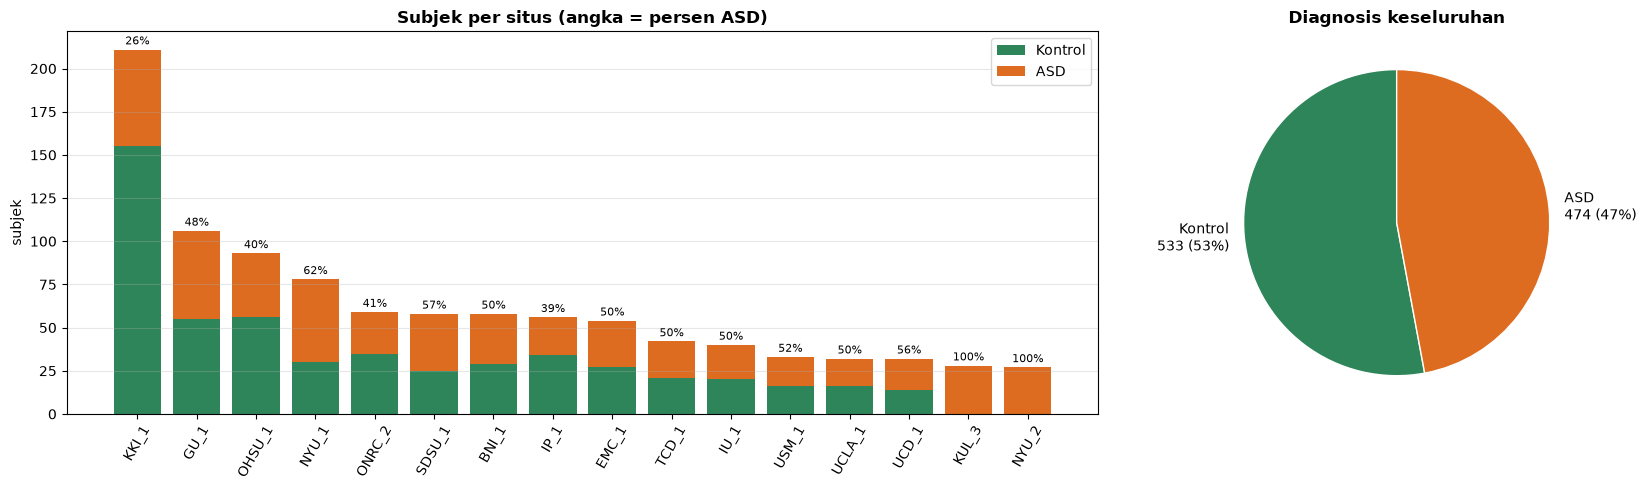

In [5]:
tab_situs = pd.crosstab(eda["Situs"], eda["Diagnosis"])
tab_situs["Total"] = tab_situs.sum(1)
tab_situs["ASD (%)"] = (tab_situs["ASD"] / tab_situs["Total"] * 100).round(1)
tab_situs = tab_situs.sort_values("Total", ascending=False)
display(tab_situs.style.set_caption(f"ABIDE II: {len(eda)} subjek | ASD {int((eda['Diagnosis'] == 'ASD').sum())} | Kontrol {int((eda['Diagnosis'] == 'Kontrol').sum())}"))
simpan_tabel(tab_situs, "diagnosis_per_situs")

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1]})
x = np.arange(len(tab_situs))
axes[0].bar(x, tab_situs["Kontrol"], color=WARNA["Kontrol"], label="Kontrol")
axes[0].bar(x, tab_situs["ASD"], bottom=tab_situs["Kontrol"], color=WARNA["ASD"], label="ASD")
for xi, (tot, p) in enumerate(zip(tab_situs["Total"], tab_situs["ASD (%)"])):
    axes[0].text(xi, tot + 3, f"{p:.0f}%", ha="center", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(tab_situs.index, rotation=60)
axes[0].set_ylabel("subjek"); axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("Subjek per situs (angka = persen ASD)", fontweight="bold")
total = eda["Diagnosis"].value_counts()
axes[1].pie(total, labels=[f"{k}\n{v} ({v / total.sum() * 100:.0f}%)" for k, v in total.items()], colors=[WARNA[k] for k in total.index],
            startangle=90, wedgeprops={"edgecolor": "white"})
axes[1].set_title("Diagnosis keseluruhan", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "02a_1_diagnosis_per_situs.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Profil Subjek: Usia, Jenis Kelamin, IQ, dan Tangan Dominan

Kelompok usia memakai pembagian yang sama dengan notebook 03, supaya ABIDE I dan II bisa dibandingkan.

,Subjek,Usia rata-rata ± SD,Rentang usia,Laki-laki (%),FIQ rata-rata ± SD,FIQ kosong
Diagnosis,,,,,,
ASD,474,14.9 ± 9.3,5.1–62.0,84.600000,106.5 ± 17.0,41
Kontrol,533,14.9 ± 9.5,5.9–64.0,67.200000,114.8 ± 12.9,57


Diagnosis,ASD,Kontrol
Kelompok usia,,
Anak-anak (<12),47.700000,59.300000
Remaja (12–18),26.600000,16.700000
Dewasa muda (18–30),20.300000,17.300000
Dewasa (>30),5.500000,6.800000


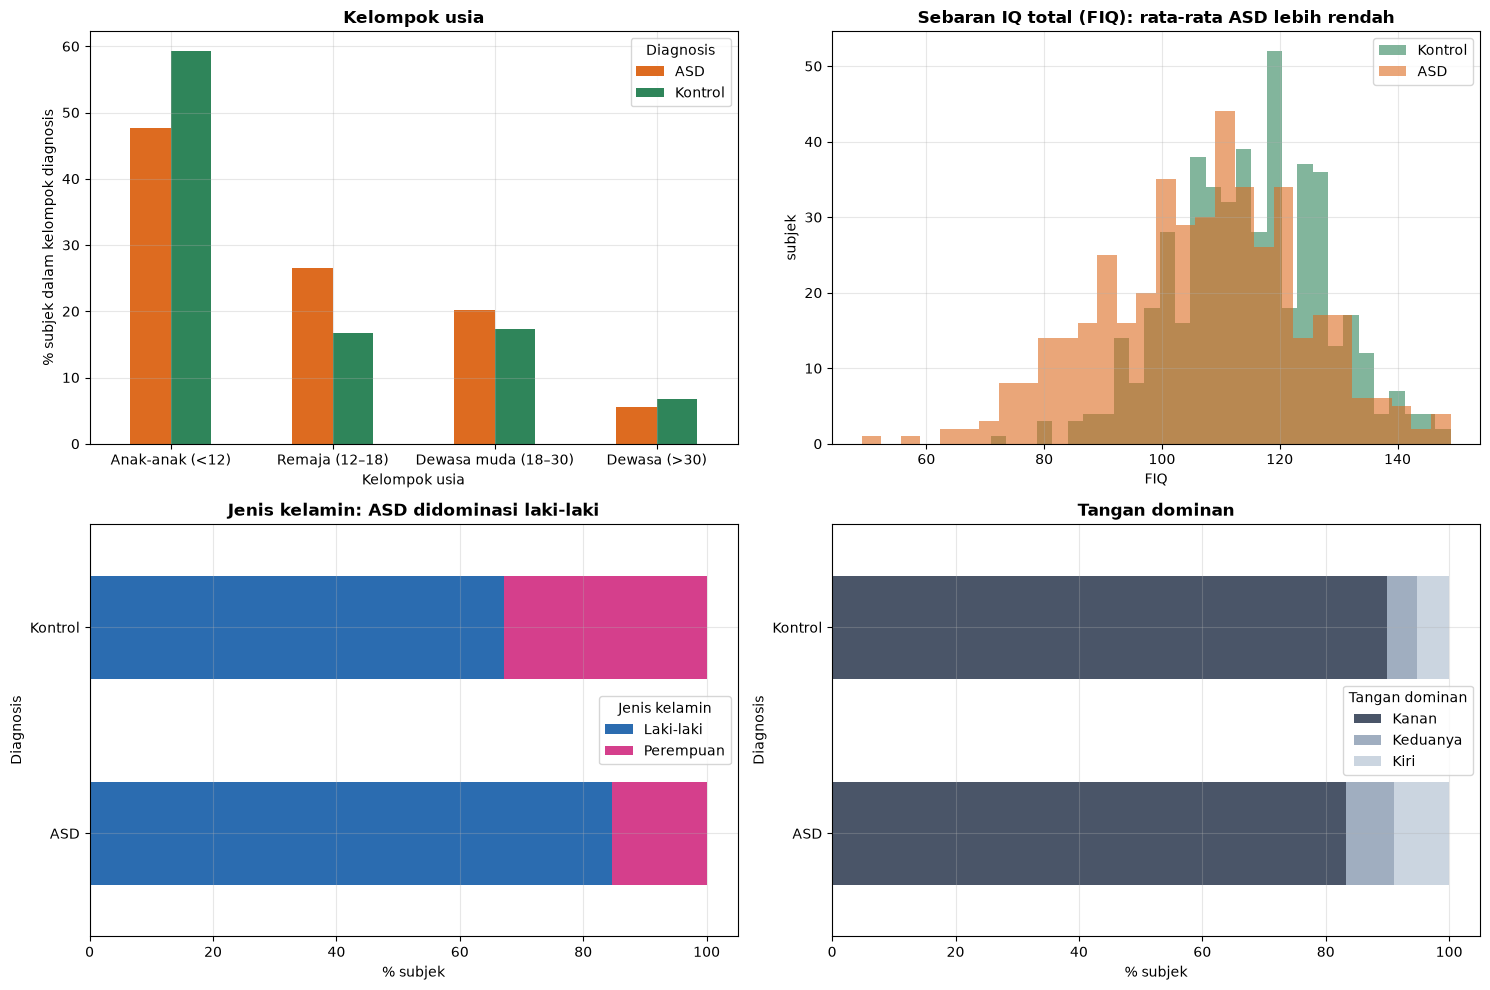

In [6]:
eda["Kelompok usia"] = pd.cut(eda["age_at_scan"], [0, 12, 18, 30, 100],
                              labels=["Anak-anak (<12)", "Remaja (12–18)", "Dewasa muda (18–30)", "Dewasa (>30)"], right=False)
eda["Jenis kelamin"] = eda["sex"].map({1: "Laki-laki", 2: "Perempuan"})
eda["Tangan dominan"] = eda["handedness_category"].map({1: "Kanan", 2: "Kiri", 3: "Keduanya"})

profil = pd.DataFrame({
    "Subjek": eda.groupby("Diagnosis").size(),
    "Usia rata-rata ± SD": eda.groupby("Diagnosis")["age_at_scan"].agg(lambda s: f"{s.mean():.1f} ± {s.std():.1f}"),
    "Rentang usia": eda.groupby("Diagnosis")["age_at_scan"].agg(lambda s: f"{s.min():.1f}–{s.max():.1f}"),
    "Laki-laki (%)": eda.groupby("Diagnosis")["sex"].agg(lambda s: (s == 1).mean() * 100),
    "FIQ rata-rata ± SD": eda.groupby("Diagnosis")["fiq"].agg(lambda s: f"{s.mean():.1f} ± {s.std():.1f}"),
    "FIQ kosong": eda.groupby("Diagnosis")["fiq"].agg(lambda s: int(s.isna().sum())),
})
display(profil.round(1).style.set_caption("Profil subjek ABIDE II per diagnosis"))
display((pd.crosstab(eda["Kelompok usia"], eda["Diagnosis"], normalize="columns") * 100).round(1)
        .style.set_caption("Persentase subjek per kelompok usia (setiap kolom = 100%)"))
simpan_tabel(profil, "profil_per_diagnosis")

fig, axs = plt.subplots(2, 2, figsize=(15, 10))
(pd.crosstab(eda["Kelompok usia"], eda["Diagnosis"], normalize="columns") * 100)[["ASD", "Kontrol"]].plot.bar(
    ax=axs[0, 0], color=[WARNA["ASD"], WARNA["Kontrol"]], rot=0)
axs[0, 0].set_ylabel("% subjek dalam kelompok diagnosis"); axs[0, 0].set_title("Kelompok usia", fontweight="bold")
for lab in ["Kontrol", "ASD"]:
    axs[0, 1].hist(eda.loc[eda["Diagnosis"] == lab, "fiq"].dropna(), bins=30, alpha=0.6, color=WARNA[lab], label=lab)
axs[0, 1].set_xlabel("FIQ"); axs[0, 1].set_ylabel("subjek"); axs[0, 1].legend()
axs[0, 1].set_title("Sebaran IQ total (FIQ): rata-rata ASD lebih rendah", fontweight="bold")
(pd.crosstab(eda["Diagnosis"], eda["Jenis kelamin"], normalize="index") * 100).plot.barh(
    ax=axs[1, 0], stacked=True, color=["#2B6CB0", "#D53F8C"])
axs[1, 0].set_xlabel("% subjek"); axs[1, 0].set_title("Jenis kelamin: ASD didominasi laki-laki", fontweight="bold")
(pd.crosstab(eda["Diagnosis"], eda["Tangan dominan"], normalize="index") * 100).plot.barh(ax=axs[1, 1], stacked=True,
                                                                                         color=["#4A5568", "#A0AEC0", "#CBD5E0"])
axs[1, 1].set_xlabel("% subjek"); axs[1, 1].set_title("Tangan dominan", fontweight="bold")
for ax in axs.ravel():
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "02a_2_profil_subjek.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Nilai Kosong per Kolom

Dari 348 kolom, banyak yang hanya terisi untuk sebagian kecil subjek. Sebabnya, setiap situs memakai kumpulan tes yang berbeda, dan sebagian tes hanya diberikan pada subjek ASD. Grafik di bawah menunjukkan rata-rata keterisian setiap kelompok kolom, dan tabel menunjukkan kolom utama.

,Kolom,Kosong (%),Kosong pada ASD (%),Kosong pada Kontrol (%)
0,dx_group,0.000000,0.000000,0.000000
1,age_at_scan,0.000000,0.000000,0.000000
2,sex,0.000000,0.000000,0.000000
3,fiq,9.700000,8.600000,10.700000
4,viq,31.300000,27.800000,34.300000
5,piq,24.000000,23.200000,24.800000
6,handedness_category,2.300000,3.200000,1.500000
7,eye_status_at_scan,0.100000,0.200000,0.000000
8,current_med_status,5.800000,5.500000,6.000000


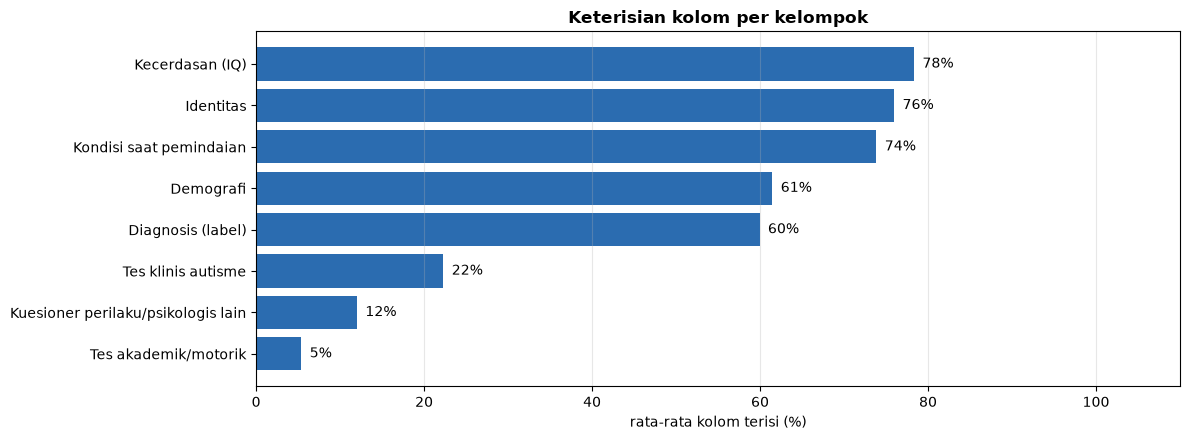

In [7]:
utama = ["dx_group", "age_at_scan", "sex", "fiq", "viq", "piq", "handedness_category", "eye_status_at_scan", "current_med_status"]
display(pd.DataFrame({"Kolom": utama, "Kosong (%)": [round(mentah[c].isna().mean() * 100, 1) for c in utama],
                      "Kosong pada ASD (%)": [round(mentah.loc[mentah["dx_group"] == 1, c].isna().mean() * 100, 1) for c in utama],
                      "Kosong pada Kontrol (%)": [round(mentah.loc[mentah["dx_group"] == 2, c].isna().mean() * 100, 1) for c in utama]})
        .style.set_caption("Nilai kosong kolom utama"))
fig, ax = plt.subplots(figsize=(12, 4.5))
r = ringkas_kelompok["Rata-rata terisi (%)"].sort_values()
ax.barh(r.index, r.values, color="#2B6CB0")
for i, v in enumerate(r.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")
ax.set_xlim(0, 110); ax.set_xlabel("rata-rata kolom terisi (%)"); ax.grid(axis="x", alpha=0.3)
ax.set_title("Keterisian kolom per kelompok", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "02a_3_keterisian_kolom.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Kolom yang Dipakai dan Dibuang

Aturannya sama dengan ABIDE I (notebook 03 bagian 6):

| Keputusan | Kolom | Alasan |
| :--- | :--- | :--- |
| **Dipakai sebagai label** | `dx_group` | target klasifikasi (ASD vs Kontrol) |
| **Dipakai sebagai fitur** | `age_at_scan`, `sex`, `fiq` | ciri subjek yang tersedia untuk ASD maupun Kontrol, dan bukan bagian dari proses diagnosis |
| **Dipakai untuk identitas/QC** | `site_id`, `participant_id` | menghubungkan fenotipik dengan data citra, dan memeriksa efek situs |
| **Dibuang** | `ados_*`, `adi_r_*`, `pdd_dsm_iv_tr`, `asd_dsm_5` | **kebocoran label**: ADOS dan ADI-R adalah instrumen yang dipakai untuk **menegakkan diagnosis** autisme, dan hampir hanya diisi untuk subjek ASD. Kalau dipakai, model "menyontek" jawaban |
| **Dibuang** | `srs_*`, `scq_*`, `aq_*`, `rbsr_*` | **kebocoran label tidak langsung**: kuesioner ini mengukur **tingkat gejala autisme** itu sendiri. Walaupun terisi untuk ASD maupun Kontrol, nilainya pada dasarnya adalah "ukuran autisme", bukan ciri otak. Tujuan penelitian adalah mendeteksi ASD dari citra otak |
| **Dibuang** | kuesioner perilaku/psikologis lain, tes akademik, obat, BMI | banyak kosong dan tidak seragam antar situs |

Sel berikut memperlihatkan pola pengisiannya: ADOS dan ADI-R hampir hanya terisi untuk subjek ASD, sedangkan SRS, SCQ, dan AQ terisi untuk kedua kelompok.

In [8]:
bocor = []
for c in ["ados_g_total", "ados_2_total", "adi_r_social_total_a", "srs_total_raw", "scq_total", "aq_total"]:
    if c in mentah:
        bocor.append({"Kolom": c, "Terisi pada ASD": int(mentah.loc[mentah["dx_group"] == 1, c].notna().sum()),
                      "Terisi pada Kontrol": int(mentah.loc[mentah["dx_group"] == 2, c].notna().sum())})
bocor = pd.DataFrame(bocor)
bocor["Hanya ASD (%)"] = (bocor["Terisi pada ASD"] / (bocor["Terisi pada ASD"] + bocor["Terisi pada Kontrol"]) * 100).round(1)
display(bocor.style.set_caption("Pengisian skor tes klinis autisme pada ASD vs Kontrol"))
seleksi = kamus.assign(Keputusan=np.select(
    [kamus["Kolom"] == "dx_group", kamus["Kolom"].isin(["age_at_scan", "sex", "fiq"]), kamus["Kolom"].isin(["site_id", "participant_id"]),
     kamus["Kelompok"].isin(["Tes klinis autisme"]) | kamus["Kolom"].isin(["pdd_dsm_iv_tr", "asd_dsm_5"])],
    ["label", "fitur", "identitas", "dibuang (kebocoran label)"], "dibuang (tidak dipakai)"))
display(seleksi["Keputusan"].value_counts().rename("Jumlah kolom").to_frame().style.set_caption("Ringkasan keputusan 348 kolom"))
simpan_tabel(seleksi.set_index("Kolom"), "seleksi_kolom")

,Kolom,Terisi pada ASD,Terisi pada Kontrol,Hanya ASD (%)
0,ados_g_total,268,46,85.400000
1,ados_2_total,233,2,99.100000
2,adi_r_social_total_a,290,0,100.000000
3,srs_total_raw,367,385,48.800000
4,scq_total,143,118,54.800000
5,aq_total,23,21,52.300000


,Jumlah kolom
Keputusan,
dibuang (tidak dipakai),235
dibuang (kebocoran label),107
fitur,3
identitas,2
label,1


## 8. Ketersediaan Data Citra (Turunan DCAN)

Nomor `participant_id` di fenotipik sama dengan nomor folder `sub-XXXXX` di data DCAN. Sel berikut memeriksa, untuk setiap subjek yang punya fenotipik, apakah turunan DCAN-nya sudah diunduh (`data/raw_dcan/abide2/`). Pemeriksaan kelengkapan dan QC gerakan yang sebenarnya dilakukan di notebook 09.

In [9]:
ada_dcan = {p.name for p in DCAN_A2.glob("sub-*")}
eda["Folder DCAN"] = ("sub-" + eda["participant_id"].astype(str)).isin(ada_dcan)
tab_citra = pd.crosstab(eda["Situs"], eda["Folder DCAN"]).rename(columns={True: "ada", False: "tidak ada"})
display(tab_citra.style.set_caption(f"Subjek ber-fenotipik yang punya folder DCAN: {int(eda['Folder DCAN'].sum())} dari {len(eda)} "
                                    f"(folder DCAN di laptop: {len(ada_dcan)}, termasuk subjek tanpa fenotipik)"))
simpan_tabel(tab_citra, "ketersediaan_dcan")

Folder DCAN,tidak ada,ada
Situs,,
BNI_1,0,58
EMC_1,2,52
GU_1,34,72
IP_1,3,53
IU_1,2,38
KKI_1,0,211
KUL_3,0,28
NYU_1,1,77
NYU_2,0,27


## 9. Ringkasan

| Temuan | Konsekuensi untuk tahap berikutnya |
| :--- | :--- |
| 16 dari 19 situs punya fenotipik (1.007 subjek, 348 kolom) | 3 situs tanpa fenotipik tidak bisa dipakai |
| Nama kolom usia berspasi (`"age_at_scan "`) | nama kolom harus dibersihkan sebelum dipakai |
| Tidak ada kode `-9999` (berbeda dengan ABIDE I) | aturan nilai kosong ABIDE I dan II berbeda, dan diseragamkan di notebook 05 |
| KUL_3 dan NYU_2 100% ASD | dikeluarkan di notebook 09 (situs satu kelas) |
| ASD didominasi laki-laki dan FIQ rata-rata lebih rendah | usia, jenis kelamin, dan FIQ dipakai sebagai fitur fenotipik (S3–S4) |
| ADOS/ADI-R hampir hanya terisi untuk ASD; SRS/SCQ/AQ mengukur gejala autisme | semua tes klinis autisme dibuang karena kebocoran label |

**Langkah berikutnya:** notebook 05 menyeragamkan kolom ABIDE I dan II, menangani nilai kosong, lalu menggabungkan keduanya.